# Calibración de reloj comparador (comparador de cuadrante)

**Instrumento.** Mitutoyo ID-S1012M, serie 12038057. Procedimiento por comparación con bloques patrón según PC-014 del INACAL. Equipo: bloques patrón de longitud grado 2 (ISO 3650), termómetro de contacto con resolución de $0.1\ ^\circ\text{C}$ y mesa de planitud de granito (model.pdf, §3.2).

**Objetivo.** Reducir las mediciones, estimar el error de indicación y su incertidumbre expandida $U(E)$, siguiendo el modelo de la sección 2.2 del informe ($\bar I$, $L_{BP}$, $\delta\alpha$, $\Delta T_i$, $\delta T$) y las ecuaciones (48)–(59) de model.pdf.

**Convención.** En todo el notebook $\sigma(\cdot)$ denota la incertidumbre típica, equivalente a $u(\cdot)$ en la notación GUM. Las longitudes están en mm y las incertidumbres en $\mu$m.

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

%matplotlib inline
pd.set_option("display.max_columns", 20)

# --- Constantes del modelo (sección 2.2 y §3.2.3 de model.pdf) ---
T0 = 20.0                 # °C, temperatura de referencia
ALPHA = 11.5e-6           # °C^-1, coeficiente del acero (bloque y comparador)
DALPHA = 1.0e-6           # °C^-1, semiamplitud de la tolerancia del coeficiente
K = 2.0                   # factor de cobertura
THETA = np.deg2rad(1.0)   # rad, inclinación máxima del vástago
D_ESC = 0.01              # mm, división de escala
M_EST = 5                 # partes de estimación visual de la división
T_PLAN_UM = 5.0           # µm, planitud de la mesa
U_CAL_UM = 0.12           # µm, incertidumbre expandida del certificado
K_CAL = 2.0
P_GF = 100.0              # gf, fuerza del palpador
D_PUNTA = 1.5             # mm, diámetro de la punta esférica
UT_CERT = 0.5             # °C, exactitud del termómetro
K_T = 2.0
DT_MODELO = 0.9           # °C, desviación térmica supuesta en el presupuesto

print(f"Constantes cargadas | T0={T0} °C, alpha={ALPHA:.1e} °C^-1, k={K:.0f}")

Constantes cargadas | T0=20.0 °C, alpha=1.2e-05 °C^-1, k=2


## 1. Serie de ascenso (datos del ensayo)

Se lee comparador/ascenso.csv, generado a partir de la tabla 3.2.1 de model.pdf con la indicación randomizada en pasos de 0.01 mm (0.00, 0.01 o 0.02 mm). El error de indicación se calcula como $E = (I - L_{BP})\times 1000$ en $\mu$m, y el alcance en ascenso como $f_e = E_{\max} - E_{\min}$ (ec. 46).

In [62]:
asc = pd.read_csv("comparador/ascenso.csv")
BU = asc["BLOQUES UTILIZADOS (mm)"].to_numpy(int)
VP = asc["VALOR PATRON (mm)"].to_numpy(float)
I = asc["INDICACION DEL COMPARADOR (mm)"].to_numpy(float)
T = asc["TEMPERATURA DEL BLOQUE (°C)"].to_numpy(float)
E = (I - VP) * 1000.0
DT_i = T - T0

tabla_asc = pd.DataFrame({
    "BU (mm)": BU, "VP (mm)": VP, "I (mm)": I,
    "T (°C)": T, "E (µm)": np.round(E, 1), "ΔT (°C)": np.round(DT_i, 1)
})
display(tabla_asc)
fe = E.max() - E.min()
print(f"fe = {E.max():.0f} - {E.min():.0f} = {fe:.0f} µm")

,BU (mm),VP (mm),I (mm),T (°C),E (µm),ΔT (°C)
0,1,1.0,1.00,21.4,0.0,1.4
1,2,2.0,2.02,21.5,20.0,1.5
2,3,3.0,3.01,21.4,10.0,1.4
3,4,4.0,4.01,21.5,10.0,1.5
4,5,5.0,5.01,21.4,10.0,1.4
5,6,6.0,6.02,21.5,20.0,1.5
6,7,7.0,7.00,21.3,0.0,1.3
7,8,8.0,8.02,21.4,20.0,1.4
8,9,9.0,9.00,21.4,0.0,1.4
9,10,10.0,10.00,21.5,0.0,1.5


fe = 20 - 0 = 20 µm


## 2. Serie original del informe (model.pdf, §3.2.1)

comparador/ascenso_original.csv conserva la tabla tal como aparece en model.pdf. Se usa para comprobar que la reducción implementada reproduce $f_e = 5\ \mu\text{m}$.

In [63]:
orig = pd.read_csv("comparador/ascenso_original.csv")
VP_o = orig["VALOR PATRON (mm)"].to_numpy(float)
I_o = orig["INDICACION DEL COMPARADOR (mm)"].to_numpy(float)
E_o = (I_o - VP_o) * 1000.0
fe_o = E_o.max() - E_o.min()
print(f"model.pdf: fe = {E_o.max():.0f} - {E_o.min():.0f} = {fe_o:.0f} µm")
print("Coincide con la ecuación (46):", bool(round(fe_o) == 5))

model.pdf: fe = 5 - 0 = 5 µm
Coincide con la ecuación (46): True


## 3. Repetibilidad (model.pdf, §3.2.2)

Cinco lecturas repetidas en $7$ mm, sorteadas en pasos de $0.01$ mm con semilla 42: $7.00,\ 7.02,\ 7.01,\ 7.01,\ 7.01$ mm. La desviación estándar muestral insesgada (Bessel) y la desviación de la media son

$$s_R = \sqrt{\frac{1}{n-1}\sum_{p=1}^n (I_p-\bar I)^2},\qquad \sigma(\bar I)=\frac{s_R}{\sqrt n}.$$

El alcance de repetibilidad es $f_w = E_{\max}-E_{\min}$ (ec. 47).

In [64]:
VP_REP = 7.0
rng_rep = np.random.default_rng(42)
rep_I = VP_REP + rng_rep.integers(0, 3, size=5) / 100.0
n_rep = len(rep_I)
s_R = rep_I.std(ddof=1) * 1000.0
u_I = s_R / np.sqrt(n_rep)
E_rep = (rep_I - VP_REP) * 1000.0
fw = E_rep.max() - E_rep.min()

print(f"n = {n_rep} | media = {rep_I.mean():.4f} mm | s_R = {s_R:.2f} µm")
print(f"u(I bar) = s_R/sqrt(n) = {u_I:.2f} µm")
print(f"fw = {E_rep.max():.0f} - {E_rep.min():.0f} = {fw:.0f} µm")
display(pd.DataFrame({"p": range(1, n_rep+1), "I (mm)": rep_I, "E (µm)": np.round(E_rep, 1)}))

n = 5 | media = 7.0100 mm | s_R = 7.07 µm
u(I bar) = s_R/sqrt(n) = 3.16 µm
fw = 20 - 0 = 20 µm


,p,I (mm),E (µm)
0,1,7.00,0.0
1,2,7.02,20.0
2,3,7.01,10.0
3,4,7.01,10.0
4,5,7.01,10.0


## 4. Error corregido térmicamente (sección 2.2)

El modelo de la sección 2.2 es

$$E = \bar I - L_{BP} + \bar I\,\delta\alpha\,\Delta T_i + L_{BP}\,\alpha_{BP}\,\delta T.$$

Aquí bloque y comparador son de acero ($\delta\alpha = \alpha_i-\alpha_{BP}=0$) y permanecen en el mismo ambiente ($\delta T=0$), por lo que los dos términos correctivos se anulan y el error corregido coincide con la diferencia directa.

In [65]:
delta_alpha = 0.0
delta_T = 0.0
E_corr = 1000.0 * (I * (1 + ALPHA * DT_i) - VP * (1 + ALPHA * (DT_i - delta_T)))
tabla_corr = pd.DataFrame({
    "VP (mm)": VP, "E directa (µm)": np.round(E, 2),
    "E corregida (µm)": np.round(E_corr, 2),
    "Diferencia (µm)": np.round(E_corr - E, 4)
})
display(tabla_corr)
print(f"Máxima corrección térmica: {np.max(np.abs(E_corr-E)):.4f} µm")

,VP (mm),E directa (µm),E corregida (µm),Diferencia (µm)
0,1.0,0.0,0.0,0.0000
1,2.0,20.0,20.0,0.0003
2,3.0,10.0,10.0,0.0002
3,4.0,10.0,10.0,0.0002
4,5.0,10.0,10.0,0.0002
5,6.0,20.0,20.0,0.0003
6,7.0,0.0,0.0,0.0000
7,8.0,20.0,20.0,0.0003
8,9.0,0.0,0.0,0.0000
9,10.0,0.0,0.0,0.0000


Máxima corrección térmica: 0.0003 µm


## 5. Componentes de incertidumbre (sección 2.2)

Evaluación tipo A para la repetibilidad y tipo B para el resto, con distribución rectangular $\sigma=a/\sqrt3$:

- $\sigma(L_{BP})$: certificado ($k=2$) más deriva ISO 3650 en rectángulo;
- $\sigma(\delta l_{cos}) = L(1-\cos\theta)/(2\sqrt3)$;
- $\sigma(\delta l_{res}) = (d/m)/(2\sqrt3)$;
- $\sigma(\delta l_{plan}) = t_{\parallel}/(2\sqrt3)$;
- $\sigma(\delta l_{fuerza}) = \delta l_{fuerza}/(2\sqrt3)$;
- $\sigma^2(\delta\alpha)$ y $\sigma^2(\Delta T_i)$, $\sigma^2(\delta T)$.

In [66]:
U_der = 0.05 + 0.5e-6 * VP                     # µm, ISO 3650 grado 1
u_LBP = np.sqrt((U_CAL_UM / K_CAL)**2 + (U_der / np.sqrt(3))**2)
u_cos = VP * (1 - np.cos(THETA)) * 1000.0 / (2*np.sqrt(3))
u_res = np.full_like(VP, (D_ESC/M_EST) * 1000.0 / (2*np.sqrt(3)))
u_plan = np.full_like(VP, T_PLAN_UM / (2*np.sqrt(3)))
d_l_fuerza = 2e-5 * P_GF**(2/3) * D_PUNTA**(-1/3) * 1000.0   # µm
u_fuerza = np.full_like(VP, d_l_fuerza / (2*np.sqrt(3)))
u_dalpha = np.sqrt(2) * DALPHA / np.sqrt(3)                  # °C^-1
u_dT = np.sqrt((UT_CERT/K_T)**2 + (DT_MODELO/np.sqrt(3))**2) # °C

componentes = pd.DataFrame({
    "L (mm)": VP, "u(I bar) (µm)": u_I, "u(L_BP) (µm)": u_LBP,
    "u(cos) (µm)": u_cos, "u(res) (µm)": u_res,
    "u(plan) (µm)": u_plan, "u(fuerza) (µm)": u_fuerza
})
display(componentes.round(3))
print(f"u(delta_alpha) = {u_dalpha:.3e} °C^-1 | u(deltaT) = {u_dT:.3f} °C")
print(f"delta_l(fuerza) = {d_l_fuerza:.3f} µm")

,L (mm),u(I bar) (µm),u(L_BP) (µm),u(cos) (µm),u(res) (µm),u(plan) (µm),u(fuerza) (µm)
0,1.0,3.162,0.067,0.044,0.577,1.443,0.109
1,2.0,3.162,0.067,0.088,0.577,1.443,0.109
2,3.0,3.162,0.067,0.132,0.577,1.443,0.109
3,4.0,3.162,0.067,0.176,0.577,1.443,0.109
4,5.0,3.162,0.067,0.220,0.577,1.443,0.109
5,6.0,3.162,0.067,0.264,0.577,1.443,0.109
6,7.0,3.162,0.067,0.308,0.577,1.443,0.109
7,8.0,3.162,0.067,0.352,0.577,1.443,0.109
8,9.0,3.162,0.067,0.396,0.577,1.443,0.109
9,10.0,3.162,0.067,0.440,0.577,1.443,0.109


u(delta_alpha) = 8.165e-07 °C^-1 | u(deltaT) = 0.577 °C
delta_l(fuerza) = 0.376 µm


## 6. Coeficientes de sensibilidad y varianza combinada

Derivando la ecuación~\ref{eq:reloj-modelo} se obtiene la ecuación~\ref{eq:reloj-varianza}:

$$\sigma_c^2(E)=[1+\delta\alpha\Delta T_i]^2\sigma^2(\bar I)+[-1+\alpha_{BP}\delta T]^2\sigma^2(L_{BP})+[\bar I\Delta T_i]^2\sigma^2(\delta\alpha)+[\bar I\delta\alpha]^2\sigma^2(\Delta T_i)+[L_{BP}\delta T]^2\sigma^2(\alpha_{BP})+[L_{BP}\alpha_{BP}]^2\sigma^2(\delta T).$$

In [67]:
c_I = 1 + delta_alpha * DT_i
c_BP = -1 + ALPHA * delta_T
c_dalpha = I * DT_i * 1000.0        # µm/°C
c_dTi = I * delta_alpha * 1000.0    # µm/°C
c_alphaBP = VP * delta_T * 1000.0   # µm/°C
c_dT = VP * ALPHA * 1000.0          # µm/°C

t1 = (c_I * u_I)**2
t2 = (c_BP * u_LBP)**2
t3 = (c_dalpha * u_dalpha)**2
t4 = (c_dTi * u_dT)**2
t5 = (c_alphaBP * u_dT)**2
t6 = (c_dT * u_dT)**2
t_cos = u_cos**2
t_res = u_res**2
t_plan = u_plan**2
t_fuerza = u_fuerza**2
u_c = np.sqrt(t1 + t2 + t_cos + t_res + t_plan + t_fuerza + t3 + t4 + t5 + t6)

balance = pd.DataFrame({
    "L (mm)": VP, "I bar": t1, "L_BP": t2, "coseno": t_cos,
    "resolución": t_res, "planitud": t_plan, "fuerza": t_fuerza,
    "delta_alpha": t3, "Delta T_i": t4, "alpha_BP": t5, "delta T": t6,
    "sigma_c(E) (µm)": u_c, "U(E), k=2 (µm)": K*u_c
})
display(balance.round(4))

,L (mm),I bar,L_BP,coseno,resolución,planitud,fuerza,delta_alpha,Delta T_i,alpha_BP,delta T,sigma_c(E) (µm),"U(E), k=2 (µm)"
0,1.0,10.0,0.0044,0.0019,0.3333,2.0833,0.0118,0.0000,0.0,0.0,0.0000,3.5263,7.0526
1,2.0,10.0,0.0044,0.0077,0.3333,2.0833,0.0118,0.0000,0.0,0.0,0.0002,3.5272,7.0543
2,3.0,10.0,0.0044,0.0174,0.3333,2.0833,0.0118,0.0000,0.0,0.0,0.0004,3.5286,7.0571
3,4.0,10.0,0.0044,0.0309,0.3333,2.0833,0.0118,0.0000,0.0,0.0,0.0007,3.5305,7.0610
4,5.0,10.0,0.0044,0.0483,0.3333,2.0833,0.0118,0.0000,0.0,0.0,0.0011,3.5330,7.0661
5,6.0,10.0,0.0044,0.0696,0.3333,2.0833,0.0118,0.0001,0.0,0.0,0.0016,3.5361,7.0722
6,7.0,10.0,0.0044,0.0947,0.3333,2.0833,0.0118,0.0001,0.0,0.0,0.0022,3.5398,7.0795
7,8.0,10.0,0.0044,0.1237,0.3333,2.0833,0.0118,0.0001,0.0,0.0,0.0028,3.5439,7.0879
8,9.0,10.0,0.0044,0.1566,0.3333,2.0833,0.0118,0.0001,0.0,0.0,0.0036,3.5487,7.0974
9,10.0,10.0,0.0044,0.1933,0.3333,2.0833,0.0118,0.0002,0.0,0.0,0.0044,3.5540,7.1080


## 7. Validación contra model.pdf (tabla 3.2.3)

El informe reporta, para $L=10$ mm, los valores $u(\bar I)=0.63$, $u(L_{BP})=0.06$, $u(\cos)=0.44$, $u(\text{res})=0.58$, $u(\text{plan})=1.44$, $u(\text{fuerza})=0.11$, $u(\alpha)\approx0$ y $u(\Delta T)=0.20$ µm. Recomponiendo la suma en cuadratura se verifica $u_c\approx1.7$ µm y $U=2u_c\approx3$ µm.

In [68]:
pdf_u = {
    "u(I bar)": 0.63, "u(L_BP)": 0.06, "u(coseno)": 0.44,
    "u(resolución)": 0.58, "u(planitud)": 1.44,
    "u(fuerza)": 0.11, "u(alpha)": 0.0, "u(Delta T)": 0.20
}
uc_pdf = np.sqrt(sum(v**2 for v in pdf_u.values()))
print("Componentes reportadas en model.pdf:")
for k, v in pdf_u.items():
    print(f"  {k:16s} = {v:5.2f} µm")
print(f"\nu_c = {uc_pdf:.3f} µm  (model.pdf: 1.7 µm)")
print(f"U(k=2) = {K*uc_pdf:.3f} µm  (model.pdf: 3 µm, por redondeo)")
assert round(uc_pdf, 1) == 1.7

Componentes reportadas en model.pdf:
  u(I bar)         =  0.63 µm
  u(L_BP)          =  0.06 µm
  u(coseno)        =  0.44 µm
  u(resolución)    =  0.58 µm
  u(planitud)      =  1.44 µm
  u(fuerza)        =  0.11 µm
  u(alpha)         =  0.00 µm
  u(Delta T)       =  0.20 µm

u_c = 1.748 µm  (model.pdf: 1.7 µm)
U(k=2) = 3.496 µm  (model.pdf: 3 µm, por redondeo)


## 8. Incertidumbre expandida sobre los datos del ensayo

Con $k=2$, $U(E)=2\,\sigma_c(E)$. Se grafica el error de indicación con sus barras de incertidumbre frente al valor patrón.

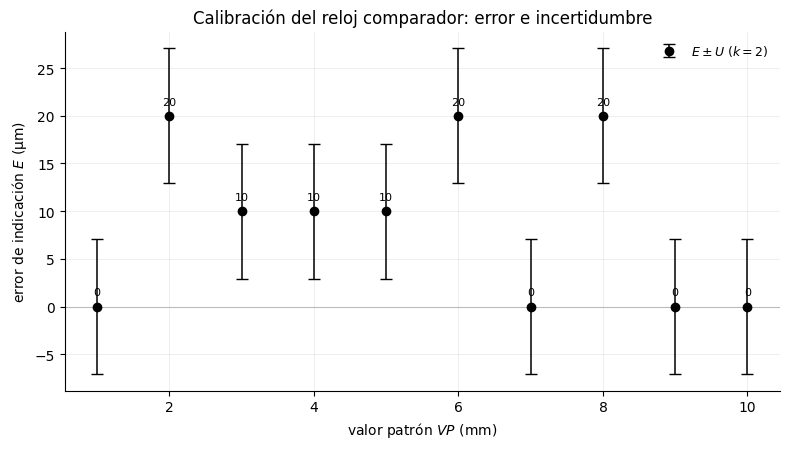

fe = 20 µm | U(E) = 7.05–7.11 µm


In [69]:
U_exp = K * u_c
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axhline(0, color="0.75", lw=0.8, zorder=1)
ax.errorbar(VP, E, yerr=U_exp, fmt="o", color="k", ms=6, capsize=4,
            elinewidth=1.1, label=r"$E \pm U$ ($k=2$)", zorder=3)
for x, y in zip(VP, E):
    ax.annotate(f"{y:.0f}", (x, y), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlabel("valor patrón $VP$ (mm)")
ax.set_ylabel("error de indicación $E$ (µm)")
ax.set_title("Calibración del reloj comparador: error e incertidumbre")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.grid(alpha=0.25, lw=0.6)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()
print(f"fe = {fe:.0f} µm | U(E) = {U_exp.min():.2f}–{U_exp.max():.2f} µm")

## 9. Cálculo estadístico elemental

Estadística directa de la serie de ascenso y de las cinco repeticiones del punto de 7 mm. Los resultados se exportan a `t6.tex` para que el informe no repita cifras escritas a mano.

In [70]:
E_bar = E.mean()
s_E = E.std(ddof=1)
I_bar_rep = rep_I.mean()
sigma_I = s_R / np.sqrt(n_rep)

assert np.isclose(E.max() - E.min(), fe)
assert np.isclose(E_rep.max() - E_rep.min(), fw)

estadistica = pd.DataFrame({
    "Magnitud": [
        "Media de la serie",
        "Desviación estándar de la serie",
        "Alcance en ascenso",
        "Media de las repeticiones",
        "Desviación estándar muestral",
        "Incertidumbre de la media",
        "Alcance de repetibilidad",
    ],
    "Símbolo": [r"$\bar E$", r"$s_E$", r"$f_e$", r"$\bar I$", r"$s_R$",
                r"$\sigma(\bar I)$", r"$f_w$"],
    "Valor": [f"{E_bar:.1f}", f"{s_E:.2f}", f"{fe:.0f}", f"{I_bar_rep:.4f}",
              f"{s_R:.2f}", f"{sigma_I:.2f}", f"{fw:.0f}"],
    "Unidad": ["µm", "µm", "µm", "mm", "µm", "µm", "µm"],
})
display(estadistica)
print(f"E_bar = {E_bar:.2f} µm | s_E = {s_E:.2f} µm | fe = {fe:.0f} µm")
print(f"I_bar = {I_bar_rep:.4f} mm | s_R = {s_R:.2f} µm | sigma(I) = {sigma_I:.2f} µm | fw = {fw:.0f} µm")

,Magnitud,Símbolo,Valor,Unidad
0,Media de la serie,$\bar E$,9.0,µm
1,Desviación estándar de la serie,$s_E$,8.76,µm
2,Alcance en ascenso,$f_e$,20,µm
3,Media de las repeticiones,$\bar I$,7.0100,mm
4,Desviación estándar muestral,$s_R$,7.07,µm
5,Incertidumbre de la media,$\sigma(\bar I)$,3.16,µm
6,Alcance de repetibilidad,$f_w$,20,µm


E_bar = 9.00 µm | s_E = 8.76 µm | fe = 20 µm
I_bar = 7.0100 mm | s_R = 7.07 µm | sigma(I) = 3.16 µm | fw = 20 µm


## 10. Exportación de tablas LaTeX

Se generan seis fragmentos en inf/c3-calibration/reloj-comparador/tablas/: datos de ascenso, repetibilidad, cálculo estadístico elemental, corrección térmica, componentes por punto y balance de incertidumbre en 10 mm, con el mismo formato (booktabs) que las tablas del pie de rey.

In [72]:
out = Path("inf/c3-calibration/reloj-comparador/tablas")
out.mkdir(parents=True, exist_ok=True)

def latex_tabla(caption, label, columnas, filas, tabular):
    lineas = [r"\begin{table}[H]", r"\centering",
              rf"\caption{{{caption}}}", rf"\label{{{label}}}",
              rf"\begin{{tabular}}{{{tabular}}}", r"\toprule",
              " & ".join(columnas) + " " + chr(92)*2, r"\midrule"]
    lineas += [f + " " + chr(92)*2 for f in filas]
    lineas += [r"\bottomrule", r"\end{tabular}", r"\end{table}", ""]
    return "\n".join(lineas)

filas1 = [f"{int(b)} & {v:.3f} & {i:.2f} & {t:.1f} & {e:.0f}"
          for b, v, i, t, e in zip(BU, VP, I, T, E)]
tex1 = latex_tabla("Error de indicación del reloj comparador, serie de ascenso (datos del ensayo).",
                   "tab:reloj-ascenso",
                   ["BU (mm)", "$VP$ (mm)", "$I$ (mm)", "$T$ (°C)", "$E$ (µm)"],
                   filas1, "rrrrr")
(out / "t1.tex").write_text(tex1, encoding="utf-8")

filas2 = [f"{p} & {x:.2f} & {(x - VP_REP)*1000:.0f}"
          for p, x in enumerate(rep_I, start=1)]
tex2 = latex_tabla("Repetibilidad en el punto de 7 mm, con $n=5$ mediciones.",
                   "tab:reloj-repetibilidad",
                   ["$p$", "$I_p$ (mm)", "$E_p$ (µm)"], filas2, "rrr")
(out / "t2.tex").write_text(tex2, encoding="utf-8")

j = int(np.argmin(np.abs(VP - 10.0)))
ucj = u_c[j]
partes = [
    (r"$\sigma(\bar I)$", u_I, t1[j]),
    (r"$\sigma(L_{BP})$", u_LBP[j], t2[j]),
    (r"$\sigma(\delta l_{cos})$", u_cos[j], t_cos[j]),
    (r"$\sigma(\delta l_{res})$", u_res[j], t_res[j]),
    (r"$\sigma(\delta l_{plan})$", u_plan[j], t_plan[j]),
    (r"$\sigma(\delta l_{fuerza})$", u_fuerza[j], t_fuerza[j]),
]
filas3 = [f"{nom} & {val:.3f} & {100*var/ucj**2:.1f}" for nom, val, var in partes]
filas3 += [rf"$\sigma_c(E)$ & {ucj:.3f} & 100.0",
           rf"$U(E)=k\,\sigma_c(E)$ & {K*ucj:.3f} & ---"]
tex3 = latex_tabla("Balance de incertidumbre del error de indicación en 10 mm.",
                   "tab:reloj-balance",
                   [r"Contribución", r"$\sigma_i$ (µm)", r"Peso en la varianza (\%)"],
                   filas3, "lrr")
(out / "t3.tex").write_text(tex3, encoding="utf-8")

filas4 = [f"{v:.3f} & {ed:.2f} & {ec:.2f} & {d:.4f}"
          for v, ed, ec, d in zip(VP, E, E_corr, E_corr - E)]
tex4 = latex_tabla("Error de indicación corregido térmicamente y comparación con el error directo.",
                   "tab:reloj-correccion",
                   ["$VP$ (mm)", "$E$ directa (µm)", "$E$ corregida (µm)", "Diferencia (µm)"],
                   filas4, "rrrr")
(out / "t4.tex").write_text(tex4, encoding="utf-8")

filas5 = [f"{L:.3f} & {a:.3f} & {b:.3f} & {c:.3f} & {d:.3f} & {e:.3f} & {f:.3f}"
          for L, a, b, c, d, e, f in componentes.round(3).to_numpy()]
tex5 = latex_tabla("Componentes de incertidumbre típica (µm) de la indicación por valor patrón (mm).",
                   "tab:reloj-componentes",
                   [r"$L$", r"$\sigma(\bar I)$", r"$\sigma(L_{BP})$",
                    r"$\sigma(\delta l_{cos})$", r"$\sigma(\delta l_{res})$",
                    r"$\sigma(\delta l_{plan})$", r"$\sigma(\delta l_{fuerza})$"],
                   filas5, "rrrrrrr")
tex5 = tex5.replace(r"\begin{table}[H]" + "\n",
                    r"\begin{table}[H]" + "\n" + r"\small" + "\n", 1)
(out / "t5.tex").write_text(tex5, encoding="utf-8")

filas6 = [f"{a} & {b} & {c} & {d}"
          for a, b, c, d in estadistica.to_numpy()]
tex6 = latex_tabla("Cálculo estadístico elemental de la serie y de las repeticiones.",
                   "tab:reloj-estadistica",
                   ["Magnitud", "Símbolo", "Valor", "Unidad"],
                   filas6, "llrr")
(out / "t6.tex").write_text(tex6, encoding="utf-8")

print("Escritos:", [p.name for p in sorted(out.glob("t*.tex"))])
print(tex3[:300])

Escritos: ['t1.tex', 't2.tex', 't3.tex', 't4.tex', 't5.tex', 't6.tex']
\begin{table}[H]
\centering
\caption{Balance de incertidumbre del error de indicación en 10 mm.}
\label{tab:reloj-balance}
\begin{tabular}{lrr}
\toprule
Contribución & $\sigma_i$ (µm) & Peso en la varianza (\%) \\
\midrule
$\sigma(\bar I)$ & 3.162 & 79.2 \\
$\sigma(L_{BP})$ & 0.067 & 0.0 \\
$\sigma(
